In [2]:
import pandas as pd 
import re
import networkx as nx
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("direcciones.csv", sep= ";", encoding= "latin1")
df = df[["VIA_CLASE","VIA_PAR","VIA_NOMBRE","NUMERO","LATITUD","LONGITUD"]]
df

,VIA_CLASE,VIA_PAR,VIA_NOMBRE,NUMERO,LATITUD,LONGITUD
0,AUTOVÍA,NaN,A-1,10000,40°29'21.84'' N,3°40'23.56'' W
1,AUTOVÍA,NaN,A-1,10000,40°29'21.45'' N,3°40'20.75'' W
2,AUTOVÍA,NaN,A-1,11000,40°29'48.13'' N,3°39'57.53'' W
3,AUTOVÍA,NaN,A-1,11000,40°29'46.27'' N,3°39'54.87'' W
4,AUTOVÍA,NaN,A-1,12000,40°30'13.33'' N,3°39'33.27'' W
...,...,...,...,...,...,...
213806,PASEO,DEL,ZURRON,49,40°28'10.77'' N,3°35'5.92'' W
213807,PASEO,DEL,ZURRON,51,40°28'10.81'' N,3°35'3.32'' W
213808,PASEO,DEL,ZURRON,53,40°28'11.34'' N,3°35'2.07'' W
213809,PASEO,DEL,ZURRON,55,40°28'11.19'' N,3°35'1.02'' W


In [4]:
def gmd_a_grados(data: pd.DataFrame) -> pd.Series:
    lista_divisores = pd.array([1,60,3600])
    valores = data.iloc[:,:-1]
    valores = valores / lista_divisores
    direccion = data.iloc[:,-1]
    direccion = direccion.map({"N" : 1, "E" : 1, "S" : -1, "W" : -1})
    return valores.sum(axis=1)*direccion

def normaliza_texto(cadena: str) -> str:
    """Mayúsculas, sin tildes ni eñes raras."""
    if cadena is None:
        return ""
    s = str(cadena).upper()
    reemplazos = {
        "Á": "A", "É": "E", "Í": "I", "Ó": "O", "Ú": "U", "Ü": "U",
        "À": "A", "È": "E", "Ì": "I", "Ò": "O", "Ù": "U",
        "Ñ": "N",
    }
    return "".join(reemplazos.get(c, c) for c in s)

regex = re.compile(r"(\d+)[°º]\s*(\d+)\'(\d+\.?\d*)\'\'\s*([NSEW])")
aux = pd.DataFrame()
cols_la = ["la_grados", "la_minutos", "la_segundos", "la_dir"]
cols_lo = ["lo_grados", "lo_minutos", "lo_segundos", "lo_dir"]

aux[cols_la] = df["LATITUD"].str.extract(regex)
aux[cols_lo] = df["LONGITUD"].str.extract(regex)
aux[cols_la[:-1] + cols_lo[:-1]] = aux[cols_la[:-1] + cols_lo[:-1]].astype("float")
df["LATITUD"] = gmd_a_grados(aux[cols_la])
df["LONGITUD"] = gmd_a_grados(aux[cols_lo])

cols = ["VIA_CLASE", "VIA_PAR", "VIA_NOMBRE"]
df[cols] = df[cols].apply(lambda col: col.map(normaliza_texto))
df

,VIA_CLASE,VIA_PAR,VIA_NOMBRE,NUMERO,LATITUD,LONGITUD
0,AUTOVIA,NAN,A-1,10000,40.489400,-3.673211
1,AUTOVIA,NAN,A-1,10000,40.489292,-3.672431
2,AUTOVIA,NAN,A-1,11000,40.496703,-3.665981
3,AUTOVIA,NAN,A-1,11000,40.496186,-3.665242
4,AUTOVIA,NAN,A-1,12000,40.503703,-3.659242
...,...,...,...,...,...,...
213806,PASEO,DEL,ZURRON,49,40.469658,-3.584978
213807,PASEO,DEL,ZURRON,51,40.469669,-3.584256
213808,PASEO,DEL,ZURRON,53,40.469817,-3.583908
213809,PASEO,DEL,ZURRON,55,40.469775,-3.583617


In [4]:
regex = r"(\d+)[°º]\s*(\d+)\'(\d+\.?\d*)\'\'\s*([NSEW])"
aux = pd.DataFrame()
aux[["la_grados","la_minutos","la_segundos","la_dir"]] = df["LATITUD"].str.extract(regex)
aux[["lo_grados","lo_minutos","lo_segundos","lo_dir"]] = df["LONGITUD"].str.extract(regex)
aux[["la_grados","la_minutos","la_segundos","lo_grados","lo_minutos","lo_segundos"]] = aux[["la_grados","la_minutos","la_segundos","lo_grados","lo_minutos","lo_segundos"]].astype("float")
aux

,la_grados,la_minutos,la_segundos,la_dir,lo_grados,lo_minutos,lo_segundos,lo_dir
0,40.0,29.0,21.84,N,3.0,40.0,23.56,W
1,40.0,29.0,21.45,N,3.0,40.0,20.75,W
2,40.0,29.0,48.13,N,3.0,39.0,57.53,W
3,40.0,29.0,46.27,N,3.0,39.0,54.87,W
4,40.0,30.0,13.33,N,3.0,39.0,33.27,W
...,...,...,...,...,...,...,...,...
213806,40.0,28.0,10.77,N,3.0,35.0,5.92,W
213807,40.0,28.0,10.81,N,3.0,35.0,3.32,W
213808,40.0,28.0,11.34,N,3.0,35.0,2.07,W
213809,40.0,28.0,11.19,N,3.0,35.0,1.02,W


In [5]:
df["LATITUD"] = aux["la_grados"] + aux["la_minutos"]/60 + aux["la_segundos"]/3600
df["LONGITUD"] = aux["lo_grados"] + aux["lo_minutos"]/60 + aux["lo_segundos"]/3600
df.loc[aux["la_dir"].isin(["W","S"]),"LATITUD"] *= -1
df.loc[aux["lo_dir"].isin(["W","S"]),"LONGITUD"] *= -1
df["VIA_PAR"]

0         NaN
1         NaN
2         NaN
3         NaN
4         NaN
         ... 
213806    DEL
213807    DEL
213808    DEL
213809    DEL
213810    DEL
Name: VIA_PAR, Length: 213811, dtype: object

In [6]:
df

,VIA_CLASE,VIA_PAR,VIA_NOMBRE,NUMERO,LATITUD,LONGITUD
0,AUTOVÍA,NaN,A-1,10000,40.489400,-3.673211
1,AUTOVÍA,NaN,A-1,10000,40.489292,-3.672431
2,AUTOVÍA,NaN,A-1,11000,40.496703,-3.665981
3,AUTOVÍA,NaN,A-1,11000,40.496186,-3.665242
4,AUTOVÍA,NaN,A-1,12000,40.503703,-3.659242
...,...,...,...,...,...,...
213806,PASEO,DEL,ZURRON,49,40.469658,-3.584978
213807,PASEO,DEL,ZURRON,51,40.469669,-3.584256
213808,PASEO,DEL,ZURRON,53,40.469817,-3.583908
213809,PASEO,DEL,ZURRON,55,40.469775,-3.583617


In [7]:
import excepciones as e
import difflib

def limpieza_fichero() -> pd.DataFrame:
    df = pd.read_csv("direcciones.csv", sep= ";", encoding= "latin1")
    df = df[["VIA_CLASE","VIA_PAR","VIA_NOMBRE","NUMERO","LATITUD","LONGITUD"]]
    regex = re.compile(r"(\d+)[°º]\s*(\d+)\'(\d+\.?\d*)\'\'\s*([NSEW])")

    aux = pd.DataFrame()
    cols_la = ["la_grados", "la_minutos", "la_segundos", "la_dir"]
    cols_lo = ["lo_grados", "lo_minutos", "lo_segundos", "lo_dir"]

    aux[cols_la] = df["LATITUD"].str.extract(regex)
    aux[cols_lo] = df["LONGITUD"].str.extract(regex)
    aux[cols_la[:-1] + cols_lo[:-1]] = aux[cols_la[:-1] + cols_lo[:-1]].astype("float")
    df["LATITUD"] = gmd_a_grados(aux[cols_la])
    df["LONGITUD"] = gmd_a_grados(aux[cols_lo])

    for col in ["VIA_CLASE", "VIA_PAR", "VIA_NOMBRE"]:
        df[col + "_N"] = df[col].fillna("").map(normaliza_texto)

    return df


def gmd_a_grados(data) -> pd.Series:
    grados, minutos, segundos, direccion = data.iloc[:,0], data.iloc[:,1], data.iloc[:,2], data.iloc[:,3]
    grados_dec = grados + minutos/60 + segundos/3600
    direccion = direccion.map({"N" : 1, "E" : 1, "S" : -1, "W" : -1})
    return grados_dec * direccion


def normaliza_texto(cadena: str) -> str:
    """Mayúsculas, sin tildes ni eñes raras."""
    if cadena is None:
        return ""
    s = str(cadena).upper()
    reemplazos = {
        "Á": "A", "É": "E", "Í": "I", "Ó": "O", "Ú": "U", "Ü": "U",
        "À": "A", "È": "E", "Ì": "I", "Ò": "O", "Ù": "U",
        "Ñ": "N",
    }
    return "".join(reemplazos.get(c, c) for c in s)


def direccion_a_coordenadas(direccion:str, df:pd.DataFrame) -> tuple:
    #1) DEFINIR EL FORMATO QUE VAMOS A ACEPTAR 
    CLASES = r"AUTOVIA|AUTOPISTA|AVENIDA|CALLE|CAMINO|CARRETERA|GLORIETA|PASAJE|PASEO|PLAZA|RONDA|TRAVESIA"
    PARES = r"DE LAS|DE LOS|DE LA|DEL|DE"
    regex_via = re.compile(rf"^\s*({CLASES})\s+({PARES})?\s+(.+)\s*$")

    #2) NORMALIZAR LA ENTRADA DEL USUARIO
    direccion_clean = normaliza_texto(direccion)

    #3) SEPARAR VIA Y NUMERO
    dir, num_raw = [p.strip() for p in direccion_clean.split(",", 1)]
    mnum = re.search(r"\d+", num_raw)
    if not mnum:
        raise ValueError(f"Número inválido en: '{num_raw}' (se esperaba un entero)")
    numero = int(mnum.group())

    #4) CASAR PATRON
    m = regex_via.match(dir)
    if not m: 
        raise ValueError(f"No se reconoce la estructura de la vía: '{dir}'")
    
    clase = m.group(1)
    par = (m.group(2) or '').strip() or None
    via = m.group(3)
    
    #5) ENCONTRAR EN EL DF
    par_cmp = par or ""  # en el CSV, ausencia de partícula suele ir como cadena vacía
    mask_exacta = (
        (df["VIA_CLASE"]  == clase) &
        (df["VIA_PAR"].fillna("") == par_cmp) &
        (df["VIA_NOMBRE"] == via) &
        (df["NUMERO"].astype("Int64") == numero)
        )
    
    candidatos = df.loc[mask_exacta, ["LATITUD","LONGITUD"]]

    #6) Si el match no es exacto -> aplicamos fuzzy 
    if len(candidatos) == 0: 
        mask_base = (
            (df["VIA_CLASE"] == clase) &
            (df["VIA_PAR"]   == par) &
            (df["NUMERO"].astype("Int64") == numero)
        )
        sub = df.loc[mask_base].copy()

        if len(sub) == 0:
            raise e.AddressNotFoundError("Calle no encontrada ni siquiera de forma aproximada")

        # calculamos similitud para cada nombre distinto
        mejor_score = -1.0
        mejor_nombre = None
        for nombre_candidato in sub["VIA_NOMBRE"].unique():
            score = difflib.SequenceMatcher(None, via, nombre_candidato).ratio()
            if score > mejor_score:
                mejor_score = score
                mejor_nombre = nombre_candidato

        if mejor_score < 0.7:
            raise e.AddressNotFoundError("Calle no encontrada ni siquiera de forma aproximada")

        candidatos = sub.loc[sub["VIA_NOMBRE"] == mejor_nombre, ["LATITUD", "LONGITUD"]]

    # 7) DEVOLVER LA PRIMERA COINCIDENCIA
    lat, lon = float(candidatos.iloc[0]["LATITUD"]), float(candidatos.iloc[0]["LONGITUD"])
    return (lat, lon)


direccion = "paseo de Sn FraNisco de Sles, 20"
lat, lon = direccion_a_coordenadas(direccion, df)
print(lat, lon)





40.440330555555555 -3.714741666666667


In [ ]:
G=nx.Graph()
#añadir nodos y aristas
G.add_node(1)
G.add_node(2)
G.add_edge(1,2)
G.add_nodes_from([3,4,5])
G.add_edges_from([(1,4),(3,4),(2,4),(3,2),(3,5)])

print(G)
print(G.nodes)
print(G.edges)

Graph with 5 nodes and 6 edges
[1, 2, 3, 4, 5]
[(1, 2), (1, 4), (2, 4), (2, 3), (3, 4), (3, 5)]


In [11]:
G.remove_node(5)

print(G)
print(G.nodes)
print(G.edges)

Graph with 4 nodes and 5 edges
[1, 2, 3, 4]
[(1, 2), (1, 4), (2, 4), (2, 3), (3, 4)]


In [ ]:
print(G[1]) #shortcut de adj, es lo mismo basicamente
print(G.adj[1])
print(G[1][2]) #informacion de la arista que va a dos

{2: {}, 4: {}}
{2: {}, 4: {}}
{}


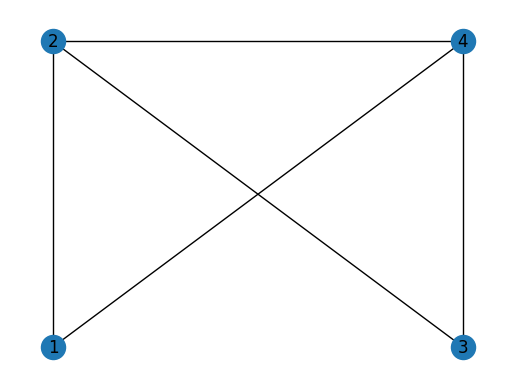

In [24]:
plot = plt.plot()
nx.draw(G, with_labels=True, pos=({1:(0,0), 2: (0,1), 3: (1,0), 4:(1,1)}))
plt.show()

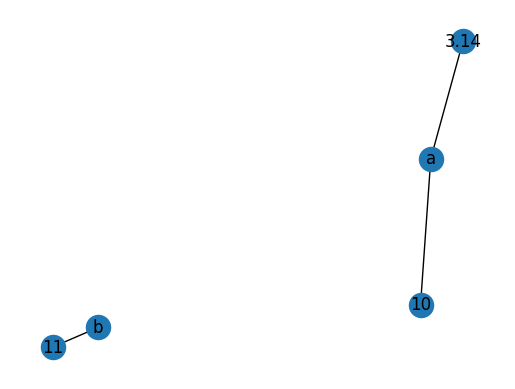

In [28]:
G2 = nx.Graph()
G2.add_nodes_from(["a","b",10,11,3.14])
G2.add_edge("a",10, object = "Una cadena", weight=1.1)
G2.add_edges_from([("a",3.14,{"object":"Otra cadena", "weight":1.2}),("b",11,{"object":"Un objeto", "weight": 1.2})])
plot = plt.plot()
nx.draw(G2, with_labels=True)
plt.show()

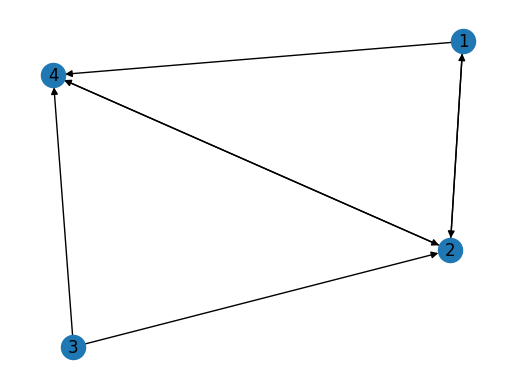

In [29]:
Gd=nx.DiGraph()
Gd.add_nodes_from([1,2,3,4])
Gd.add_edges_from([(1,2),(2,1),(1,4),(3,4),(2,4),(4,2),(3,2)])
plot = plt.plot()
nx.draw(Gd, with_labels=True)
plt.show()

In [ ]:
#grados de los nodos
print(G.degree)
print(G.degree(2))
print(Gd.in_degree())
print(Gd.out_degree())

[(1, 2), (2, 3), (3, 2), (4, 3)]
3
[(1, 1), (2, 3), (3, 0), (4, 3)]
[(1, 2), (2, 2), (3, 2), (4, 1)]


In [ ]:
#componentes conexas en grafo no dirigido
componentes = nx.connected_components(G2)
print(list(componentes))

[{10, 3.14, 'a'}, {11, 'b'}]


In [ ]:
#simplemente conexas y fuertemente conexas
componentes_debil = nx.weakly_connected_components(Gd)
componentes_fuertes = nx.strongly_connected_components(Gd)
print(list(componentes_debil))
print(list(componentes_fuertes))

[{1, 2, 3, 4}]
[{1, 2, 4}, {3}]


[1, 4, 3]


{(1, 4): Text(0.5576695603758455, 0.10866797515393112, '1'),
 (4, 3): Text(-0.44231967935018424, 0.35658295188027844, '2')}

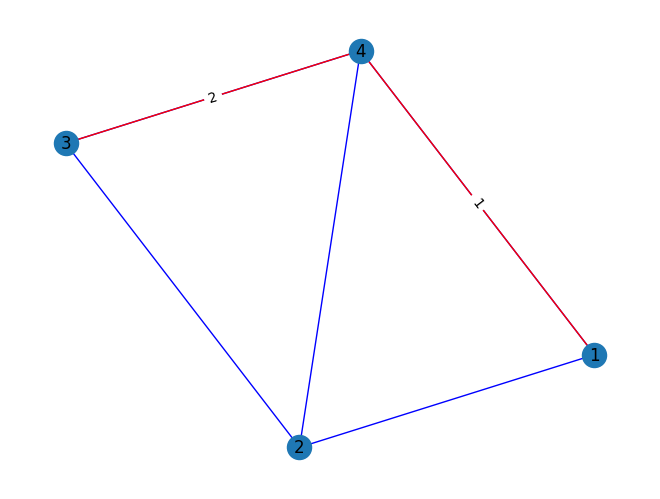

In [42]:
camino = nx.shortest_path(G,1,3)
print(camino)
pos = nx.spring_layout(G)
nx.draw(G,with_labels=True, pos=pos, edge_color = "b")
nx.draw_networkx_edges(G,pos=pos,arrows=True,edgelist=[(1,4),(4,3)], edge_color="r")
nx.draw_networkx_edge_labels(G,pos=pos,edge_labels={(1,4):"1", (4,3):"2"})